# Лабораторная работа 13. SFT и LoRA с нуля (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 5:** дообучение и выравнивание

**Цель.** Реализовать supervised fine-tuning на инструкциях и LoRA без библиотеки `peft`, а также исследовать низкоранговую природу адаптации.

**Что нужно сдать:**
1. LoRA-слой (инъекция, масштабирование, слияние весов) с проверкой эквивалентности после слияния.
2. SFT предобученной модели на инструкциях с маскированием промпта и без него.
3. Сравнение рангов и целевых модулей.
4. Спектральный анализ $\Delta W$ после полного fine-tuning.
5. Измерение забывания: perplexity на общем корпусе до и после SFT.

**Данные.** Синтетические инструкции с автоматической проверкой ответа: разворот слова, сортировка чисел, перевод в верхний регистр, сложение. Это позволяет измерять exact match. В полном режиме можно добавить реальный инструкционный датасет (Alpaca и аналоги).

**Теория. LoRA.** Для замороженной матрицы $W_0 \in \mathbb{R}^{d_{out}\times d_{in}}$:
$$
h = W_0 x + \frac{\alpha}{r} B A x,\qquad A \in \mathbb{R}^{r\times d_{in}},\; B \in \mathbb{R}^{d_{out}\times r},
$$
где $A$ инициализируется случайно, $B = 0$ (в начале обучения модель не меняется). После обучения веса сливаются: $W = W_0 + \frac{\alpha}{r}BA$, и инференс не замедляется. Гипотеза малой внутренней размерности (Aghajanyan et al., 2020): полезное обновление при дообучении лежит в подпространстве малой размерности.

In [1]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.6.0+cu126, device=cuda, FAST_DEV_RUN=True


In [2]:
# ==== Загрузка предобученных моделей Hugging Face ====
from transformers import AutoTokenizer, AutoModelForCausalLM

def load_lm(name, dtype=None):
    tok = AutoTokenizer.from_pretrained(name)
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    dtype = dtype or (torch.float16 if DEVICE == "cuda" else torch.float32)
    try:
        model = AutoModelForCausalLM.from_pretrained(name, dtype=dtype)
    except TypeError:
        model = AutoModelForCausalLM.from_pretrained(name, torch_dtype=dtype)
    return model.to(DEVICE).eval(), tok

@torch.no_grad()
def perplexity(model, tok, text, max_len=512, stride=256, max_windows=None):
    ids = tok(text, return_tensors="pt").input_ids.to(DEVICE)
    nll, cnt, prev = 0.0, 0, 0
    for i, start in enumerate(range(0, ids.size(1) - 1, stride)):
        if max_windows and i >= max_windows: break
        end = min(start + max_len, ids.size(1)); x = ids[:, start:end]
        tgt = x.clone(); tgt[:, : max(0, prev - start)] = -100
        out = model(x, labels=tgt)
        n = (tgt[:, 1:] != -100).sum().item(); nll += out.loss.float().item() * n; cnt += n; prev = end
        if end == ids.size(1): break
    return math.exp(nll / cnt)

In [3]:
BASE = "HuggingFaceTB/SmolLM2-135M" if FAST_DEV_RUN else "Qwen/Qwen2.5-0.5B"
model, tok = load_lm(BASE, dtype=torch.float32)
print(BASE, f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M параметров")

HuggingFaceTB/SmolLM2-135M 134.5M параметров


## 0. Синтетический инструкционный датасет

In [4]:
WORDS = ("apple river garden window silver planet orange monkey castle pencil bridge forest winter summer rocket "
         "dragon basket mirror candle thunder library coffee guitar island pirate jungle ladder magnet needle ocean "
         "puzzle rabbit saddle tomato violin wizard yellow zebra anchor butter circle").split()
TEMPLATE = "### Instruction:\n{inst}\n### Response:\n"

def make_example(rng):
    kind = rng.choice(["reverse", "sort", "upper", "add"])
    if kind == "reverse":
        w = rng.choice(WORDS); return kind, f"Reverse the letters of the word: {w}", w[::-1]
    if kind == "sort":
        xs = rng.sample(range(1, 100), rng.randint(3, 5)); return kind, "Sort in ascending order: " + ", ".join(map(str, xs)), ", ".join(map(str, sorted(xs)))
    if kind == "upper":
        ph = " ".join(rng.sample(WORDS, 2)); return kind, f"Convert to uppercase: {ph}", ph.upper()
    a, b = rng.randint(10, 99), rng.randint(10, 99); return kind, f"What is {a} plus {b}?", str(a + b)

rng = random.Random(0)
train_set = [make_example(rng) for _ in range(2000)]
rng = random.Random(1)
test_set = [make_example(rng) for _ in range(40 if FAST_DEV_RUN else 400)]
for e in train_set[:4]: print(e)

('add', 'What is 63 plus 15?', '78')
('upper', 'Convert to uppercase: saddle rabbit', 'SADDLE RABBIT')
('add', 'What is 48 plus 71?', '119')
('upper', 'Convert to uppercase: zebra summer', 'ZEBRA SUMMER')


## 1. LoRA-слой

Реализуйте обёртку над `nn.Linear`:
- исходный вес заморожен;
- $A \sim \mathcal{N}(0, 1/r)$ (или Kaiming), $B = 0$;
- `merge()` возвращает обычный `nn.Linear` с весом $W_0 + \frac{\alpha}{r}BA$.

Функция `inject_lora` заменяет линейные слои, имена которых заканчиваются на один из `targets`, и замораживает все остальные параметры.

In [5]:
class LoRALinear(nn.Module):
    def __init__(self, base: nn.Linear, r=8, alpha=16):
        super().__init__()
        self.base, self.r, self.scale = base, r, alpha / r
        for p in self.base.parameters(): p.requires_grad_(False)
        self.A = nn.Parameter(base.weight.new_empty(r,base.in_features))
        nn.init.kaiming_uniform_(self.A,a=math.sqrt(5))
        self.B = nn.Parameter(base.weight.new_zeros(base.out_features,r))
        self.train(base.training)
    def forward(self, x):
        if not self.training:
            weight = torch.add(self.base.weight, self.B @ self.A, alpha=self.scale)
            return F.linear(x, weight, self.base.bias)
        return self.base(x) + self.scale * F.linear(F.linear(x,self.A),self.B)
    def merge(self):
        layer = copy.deepcopy(self.base)
        with torch.no_grad():
            layer.weight.add_(self.B @ self.A, alpha=self.scale)
        return layer

ATTN = ("q_proj", "k_proj", "v_proj", "o_proj"); MLP = ("gate_proj", "up_proj", "down_proj")

def inject_lora(model, targets, r=8, alpha=16):
    for p in model.parameters(): p.requires_grad_(False)
    for parent in list(model.modules()):
        for name, layer in list(parent.named_children()):
            if isinstance(layer,nn.Linear) and name.endswith(targets):
                setattr(parent,name,LoRALinear(layer,r,alpha))
    return model

def merge_lora(model):
    for name, mod in list(model.named_modules()):
        for child_name, child in list(mod.named_children()):
            if isinstance(child, LoRALinear): setattr(mod, child_name, child.merge())
    return model

def trainable(model): return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [6]:
import copy
m = inject_lora(copy.deepcopy(model), ATTN + MLP, r=4)
with torch.no_grad():
    for mod in m.modules():
        if isinstance(mod, LoRALinear): mod.B.normal_(0, 0.02)             # ненулевой B для теста
ids = tok("Hello world, this is a test", return_tensors="pt").input_ids.to(DEVICE)
with torch.no_grad():
    y1 = m(ids).logits; y2 = merge_lora(m)(ids).logits
print("обучаемых параметров:", trainable(inject_lora(copy.deepcopy(model), ATTN + MLP, r=4)), "max|Δ| после слияния:", (y1 - y2).abs().max().item())
assert torch.allclose(y1, y2, atol=1e-4); del m

обучаемых параметров: 1221120 max|Δ| после слияния: 0.0


## 2. SFT с маскированием промпта

Последовательность: `TEMPLATE.format(inst) + response + eos`. С маскированием метки токенов промпта равны −100, и loss считается только по ответу. Без маскирования loss считается по всей последовательности.

Оценка — exact match greedy-ответа (до перевода строки или eos) по каждому типу задачи.

In [7]:
def build_batch(examples, mask_prompt=True):
    seqs, labels = [], []
    for _, inst, response in examples:
        p = tok.encode(TEMPLATE.format(inst=inst),add_special_tokens=False)
        a = tok.encode(response,add_special_tokens=False) + [tok.eos_token_id]
        seqs.append(torch.tensor(p+a))
        labels.append(torch.tensor(([-100]*len(p) if mask_prompt else p)+a))
    pad = nn.utils.rnn.pad_sequence
    x = pad(seqs,batch_first=True,padding_value=tok.pad_token_id)
    y = pad(labels,batch_first=True,padding_value=-100)
    att = torch.arange(x.size(1))[None,:] < torch.tensor([len(s) for s in seqs])[:,None]
    return x.to(DEVICE), y.to(DEVICE), att.to(DEVICE)

def sft(model, steps, lr=2e-3, B=8, mask_prompt=True, seed=SEED):
    set_seed(seed); params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.0); rng = random.Random(seed); hist = []
    model.train()
    for s in range(steps):
        x, y, att = build_batch(rng.sample(train_set, B), mask_prompt)
        loss = model(x,attention_mask=att,labels=y).loss
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(params,1.0)
        opt.step()
        hist.append(loss.item())
    model.eval(); return hist

@torch.no_grad()
def evaluate(model, data=None, max_new=12):
    data = data or test_set; model.eval(); res = {}
    for kind, inst, resp in data:
        ids = tok(TEMPLATE.format(inst=inst), return_tensors="pt", add_special_tokens=False).input_ids.to(DEVICE)
        out = model.generate(ids, max_new_tokens=max_new, do_sample=False, pad_token_id=tok.pad_token_id, eos_token_id=tok.eos_token_id)
        ans = tok.decode(out[0, ids.size(1):], skip_special_tokens=True).split("\n")[0].strip()
        res.setdefault(kind, []).append(ans == resp)
    out = {k: float(np.mean(v)) for k, v in res.items()}; out["всего"] = float(np.mean([x for v in res.values() for x in v]))
    return out

general_text = load_shakespeare()[:30_000]
MAXW = 6 if FAST_DEV_RUN else 30
base_eval = evaluate(model); base_ppl = perplexity(model, tok, general_text, max_windows=MAXW)
print("до SFT:", {k: round(v, 2) for k, v in base_eval.items()}, "perplexity на общем тексте:", round(base_ppl, 2))

до SFT: {'sort': 0.0, 'add': 0.0, 'reverse': 0.0, 'upper': 0.0, 'всего': 0.0} perplexity на общем тексте: 28.0


In [8]:
STEPS = 60 if FAST_DEV_RUN else 600
import pandas as pd
rows = []
for mask in (True, False):
    m = inject_lora(copy.deepcopy(model), ATTN + MLP, r=8)
    t0 = time.time(); h = sft(m, STEPS, mask_prompt=mask); ev = evaluate(m)
    rows.append({"маскирование промпта": mask, **{k: round(v, 3) for k, v in ev.items()}, "время, c": round(time.time() - t0)})
    if mask: lora_model = m
    else: del m
pd.DataFrame(rows)

   маскирование промпта  sort    add  reverse  upper  всего  время, c
0                  True   0.0  0.467    0.167   1.00  0.325       100
1                 False   0.0  0.000    0.000   0.75  0.075       103

## 3. Ранги и целевые модули

С маскированием промпта сравните:
- ранги $r \in \{1, 4, 16, 64\}$ (в `FAST_DEV_RUN` — $\{1, 8\}$) для всех модулей, $\alpha = 2r$;
- при $r = 8$: только attention, только MLP, все модули.

Для каждой конфигурации укажите число обучаемых параметров, exact match и perplexity на общем тексте.

In [9]:
RANKS = [1, 8] if FAST_DEV_RUN else [1, 4, 16, 64]
configs = [(f"r={r}, все", ATTN + MLP, r) for r in RANKS] + [("r=8, attention", ATTN, 8), ("r=8, MLP", MLP, 8)]
rows = []
for name, targets, r in configs:
    if targets == ATTN + MLP and r == 8:
        current = lora_model
    else:
        current = inject_lora(copy.deepcopy(model),targets,r,alpha=2*r)
        sft(current,STEPS)
    rows.append({"вариант":name,"обучаемых":trainable(current),"exact match":evaluate(current)["всего"],
                 "PPL":perplexity(current,tok,general_text,max_windows=MAXW)})
    del current
display(pd.DataFrame(rows))

          вариант  обучаемых  exact match        PPL
0        r=1, все     305280        0.350  33.251274
1        r=8, все    2442240        0.325  38.039253
2  r=8, attention     921600        0.375  36.073901
3        r=8, MLP    1520640        0.300  32.905941

## 4. Спектр $\Delta W$ при полном fine-tuning

Выполните полный fine-tuning копии модели на той же задаче (меньший LR, например 3e-5) и для матриц `q_proj`, `v_proj`, `down_proj` нескольких слоёв посчитайте сингулярные значения $\Delta W = W_{ft} - W_0$. Постройте долю энергии $\sum_{i\le k}\sigma_i^2 / \sum\sigma_i^2$ в зависимости от $k$ и сравните со случайной гауссовой матрицей того же размера и нормы. Сколько компонент нужно для 50% и 90% энергии?

полный FT: {'sort': 0.0, 'add': 0.8666666666666667, 'reverse': 0.0, 'upper': 1.0, 'всего': 0.425}, 21 c


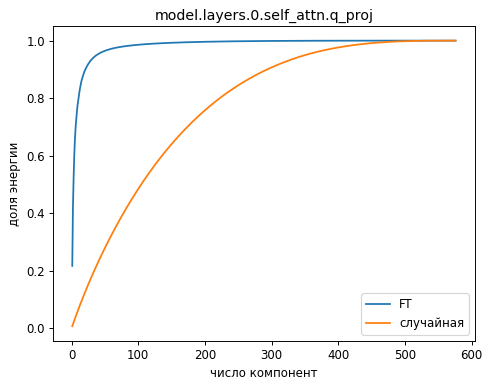

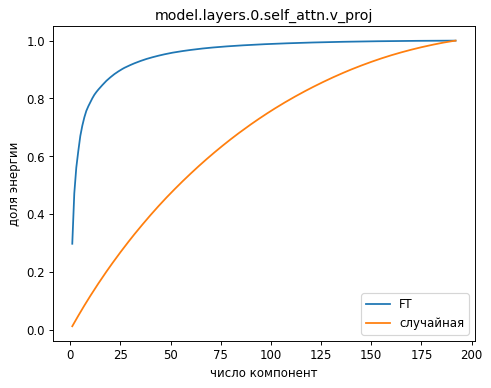

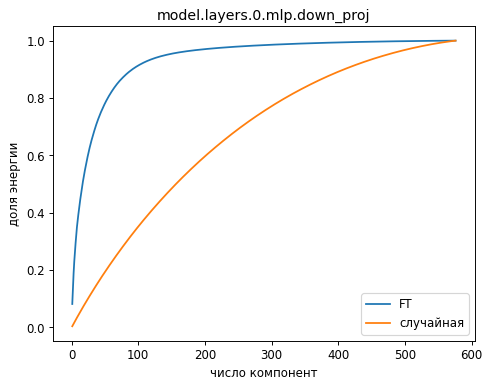

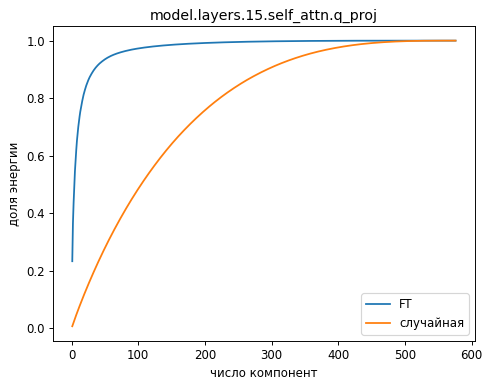

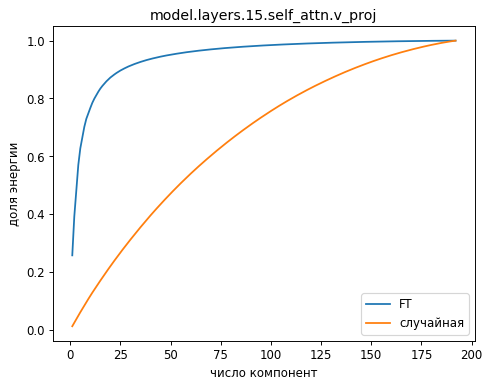

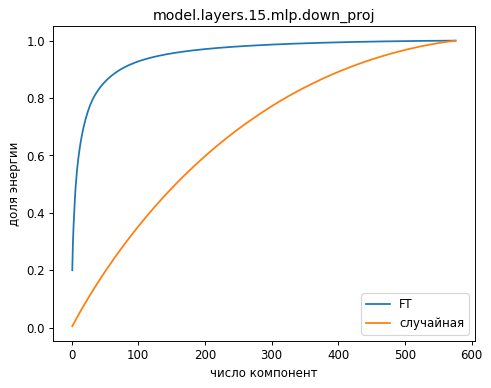

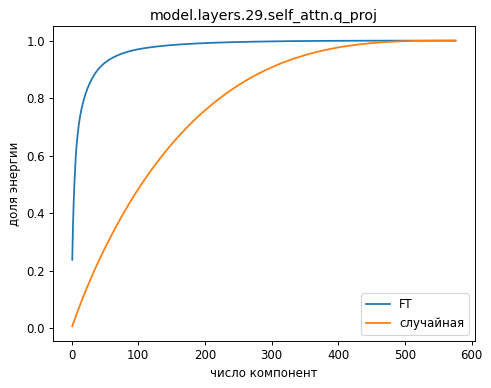

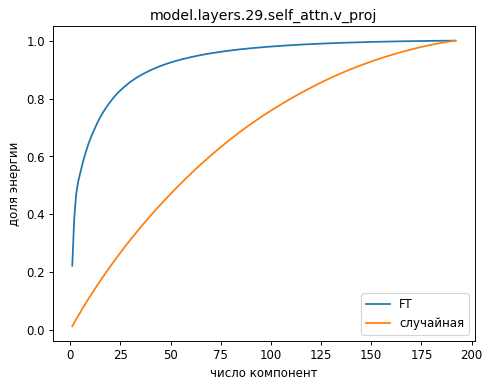

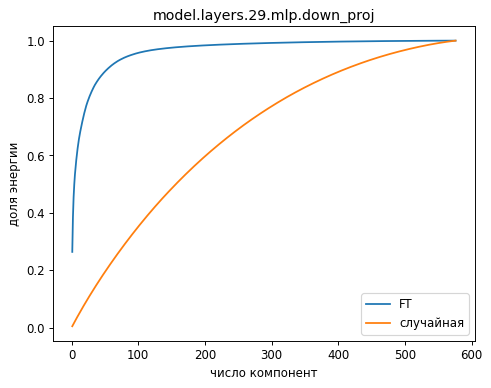

                                слой    матрица  k50  k90
0    model.layers.0.self_attn.q_proj         FT    3   21
1    model.layers.0.self_attn.q_proj  случайная  105  294
2    model.layers.0.self_attn.v_proj         FT    3   26
3    model.layers.0.self_attn.v_proj  случайная   54  140
4       model.layers.0.mlp.down_proj         FT   17   92
5       model.layers.0.mlp.down_proj  случайная  157  409
6   model.layers.15.self_attn.q_proj         FT    5   35
7   model.layers.15.self_attn.q_proj  случайная  105  294
8   model.layers.15.self_attn.v_proj         FT    4   26
9   model.layers.15.self_attn.v_proj  случайная   55  140
10     model.layers.15.mlp.down_proj         FT    7   74
11     model.layers.15.mlp.down_proj  случайная  157  410
12  model.layers.29.self_attn.q_proj         FT    5   40
13  model.layers.29.self_attn.q_proj  случайная  105  294
14  model.layers.29.self_attn.v_proj         FT    4   41
15  model.layers.29.self_attn.v_proj  случайная   55  140
16     model.l

In [10]:
full = copy.deepcopy(model)
for p in full.parameters(): p.requires_grad_(True)
t0 = time.time(); h_full = sft(full, STEPS, lr=3e-5); ev_full = evaluate(full)
print(f"полный FT: {ev_full}, {time.time() - t0:.0f} c")

base_layers = dict(model.named_modules())
rows = []
layers = {0, model.config.num_hidden_layers//2, model.config.num_hidden_layers-1}
for name, layer in full.named_modules():
    if not name.endswith(("q_proj","v_proj","down_proj")) or int(name.split(".")[2]) not in layers:
        continue
    delta = (layer.weight.detach()-base_layers[name].weight.detach()).float().cpu()
    rnd = torch.randn_like(delta)
    rnd *= delta.norm()/rnd.norm()
    for kind, mat in [("FT",delta),("случайная",rnd)]:
        s = torch.linalg.svdvals(mat).square()
        energy = s.cumsum(0)/s.sum()
        rows.append([name,kind,int(torch.searchsorted(energy,0.5))+1,int(torch.searchsorted(energy,0.9))+1])
        plt.plot(range(1,len(s)+1),energy,label=kind)
    plt.title(name)
    plt.xlabel("число компонент")
    plt.ylabel("доля энергии")
    plt.legend()
    plt.show()
display(pd.DataFrame(rows,columns=["слой","матрица","k50","k90"]))

## 5. Забывание

Сравните perplexity на общем тексте и exact match для: базовой модели, LoRA r=8 (все модули), полного fine-tuning. Объясните, почему LoRA обычно забывает меньше (Biderman et al., 2024, «LoRA Learns Less and Forgets Less»).

In [11]:
rows = [{"модель": "базовая", "exact match": base_eval["всего"], "ppl общий текст": base_ppl},
        {"модель": "LoRA r=8", "exact match": evaluate(lora_model)["всего"], "ppl общий текст": perplexity(lora_model, tok, general_text, max_windows=MAXW)},
        {"модель": "полный FT", "exact match": ev_full["всего"], "ppl общий текст": perplexity(full, tok, general_text, max_windows=MAXW)}]
pd.DataFrame(rows).round(3)

      модель  exact match  ppl общий текст
0    базовая        0.000           27.997
1   LoRA r=8        0.325           38.039
2  полный FT        0.425           28.483

## Вопросы

1. Почему $B$ инициализируется нулём, а $A$ — случайно? Что будет при обратной инициализации и при нулевой инициализации обеих матриц?
2. Зачем множитель $\alpha/r$? Как он влияет на перенос learning rate между рангами (сравните с rsLoRA, где множитель $\alpha/\sqrt r$)?
3. Как маскирование промпта влияет на качество и почему? В каких задачах обучение на промпте может помогать?
4. Что показывает спектральный анализ $\Delta W$ о гипотезе малой внутренней размерности? Согласуется ли это с тем, как качество зависит от ранга LoRA?
5. Сколько памяти экономит LoRA при обучении модели 7B в BF16 с Adam по сравнению с полным fine-tuning? Что даёт дополнительная 4-битная квантизация базовой модели (QLoRA)?

### Ответы

1. При $B=0$ добавка BA равна нулю. Первый градиент обновляет B через ненулевую A. При обратной инициализации первой обновится A. Если обе равны нулю, обе производные произведения равны нулю и адаптер не сдвигается.

2. $\frac{\alpha}{r}$ задаёт масштаб добавки и её градиентов. Смена ранга меняет число слагаемых и масштаб шага даже при том же LR. В опыте $\alpha=2r$ фиксирует множитель 2. В rsLoRA используют $\frac{\alpha}{\sqrt{r}}$, чтобы при больших рангах эффективные обновления не затухали так быстро.

3. Маска исключает предсказание инструкции из loss. Инструкция остаётся контекстом, а все учитываемые ошибки относятся к ответу. При коротких ответах это меняет баланс сигнала. Обучение на промпте может помогать освоить новый доменный язык или формат диалога. Сравниваю exact match по каждому типу задач.

4. Если первые несколько сингулярных значений несут большую долю энергии обновления, матрицу $\Delta W$ можно приблизить низким рангом. Сравниваю $k_{50}$ и $k_{90}$ с равной по норме случайной матрицей. Это согласуется с возможностью малых адаптеров, но спектр одной матрицы сам по себе не предсказывает exact match всей модели.

5. Для 7B веса BF16 занимают 14 ГБ, градиенты BF16 ещё 14, два FP32-момента Adam ещё 56. Всего около 84 ГБ, с отдельной FP32-копией весов — около 112. LoRA оставляет 14 ГБ основы и небольшие обучаемые адаптеры с их состояниями. Экономия порядка 70–98 ГБ до учёта адаптеров и активаций. QLoRA снижает сырые 14 ГБ базовых весов до 3,5 ГБ плюс данные шкал.
